In [1]:
import pandas as pd
import os
import multiprocessing as mp
import numpy as np

In [2]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype']='none'

## Presence in other sciarid genomes
B. coprophila HGT is determined to be present in other sciarids from tree-based homology inference

In [19]:
df=pd.read_csv("outputs/SI_inspection_bradysia_6_23_2026.tsv",sep="\t",index_col=0)
htgdf=df[~df.annotation.isin(['Reject','Other direction'])]
upsetdf=pd.DataFrame(columns=['Bradysia coprophila',
 'Bradysia impatiens',
 'Bradysia odoriphaga',
 'Lycoriella ingenua',
 'Pseudolycoriella hygida'])
import ast
for index, row in htgdf.iterrows():
    species=row.sciarid_species.split(", ")
    for sp in species:
        for seq in ast.literal_eval(row.cluster_seqs):
            upsetdf.loc[seq,sp]=True
upsetdf=upsetdf.fillna(False)
upsetdf.to_csv('outputs/homologs_in_other_sciarids_per_gene.tsv',sep='\t')

/tmp/ipykernel_3907121/3852178131.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  upsetdf=upsetdf.fillna(False)


In [33]:
for index, row in upsetdf.iterrows():
    if row['Pseudolycoriella hygida']:
        p=5
    elif row['Lycoriella ingenua']:
        p=4
    elif row['Bradysia impatiens']:
        p=3
    elif row['Bradysia odoriphaga']:
        p=2
    elif row['Bradysia coprophila']:
        p=1
    upsetdf.loc[index,'phylostratum']=p

In [39]:
upsetdf.to_csv('outputs/homologs_in_other_sciarids_per_gene.tsv',sep='\t')

In [37]:
from collections import Counter
Counter(htgdf['age'])

Counter({5.0: 533, 4.0: 250, 1.0: 45, 2.0: 27, 3.0: 79})

In [38]:
for x, dfi in htgdf.groupby('age'):
    print(x,dfi.n_cluster_seqs.sum())

1.0 53
2.0 28
3.0 106
4.0 330
5.0 1000


In [36]:
from collections import Counter
Counter(upsetdf.phylostratum)

Counter({5.0: 1000, 4.0: 330, 1.0: 53, 2.0: 28, 3.0: 106})

In [30]:
!pip install UpSetPlot

In [ ]:
import pandas as pd
from upsetplot import UpSet, from_indicators


# Read TSV
df = pd.read_csv("outputs/homologs_in_other_sciarids_per_gene.tsv", sep="\t")

# Rename first column to something clearer
df = df.rename(columns={"Unnamed: 0": "gene_id"})

# Species columns are the Boolean membership columns
species_cols = [
    "Bradysia coprophila",
    "Bradysia odoriphaga",
    "Bradysia impatiens",
    "Lycoriella ingenua",
    "Pseudolycoriella hygida",
]

# Make sure they are Boolean
df[species_cols] = df[species_cols].astype(bool)

# Convert Boolean indicator columns to UpSetPlot format
upset_data = from_indicators(species_cols, data=df)

# Plot
UpSet(
    upset_data,
    subset_size="count",
    show_counts=True,
    sort_by="cardinality",
    sort_categories_by="input",
    
    show_percentages=True
).plot()

plt.savefig('figures/upset_plot_homology.svg')

In [9]:
upsetdf=pd.read_csv('outputs/homologs_in_other_sciarids_per_gene.tsv',sep='\t',index_col=0)

## Microsynteny analysis 

### run reciprocal diamond blastp searches 

In [7]:
!mkdir /n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases

In [7]:
import pandas as pd
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col='accession')

In [9]:
!singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond makedb --in "ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta" -d '/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/coprophila_db'

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 112
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Database input file: ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta
Opening the database file...  [0.027s]
Loading sequences...  [0.028s]
Masking sequences...  [0.05s]
Writing sequences...  [0.006s]
Hashing sequences...  [0.003s]
Loading sequences...  [0s]
Writing trailer...  [0s]
Closing the input file...  [0s]
Closing the database file...  [0.03s]

Database sequences  16462
  Database letters  8889989
     Database hash  ab93fde42b65375b378abdc60ffa05fa
        Total time  0.147000s


In [10]:
!singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond makedb --in "ncbi_dataset/data/GCA_016920775.1/protein.faa" -d '/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/odoriphaga_db'

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 112
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Database input file: ncbi_dataset/data/GCA_016920775.1/protein.faa
Opening the database file...  [0.012s]
Loading sequences...  [0.027s]
Masking sequences...  [0.055s]
Writing sequences...  [0.006s]
Hashing sequences...  [0.003s]
Loading sequences...  [0s]
Writing trailer...  [0s]
Closing the input file...  [0s]
Closing the database file...  [0.019s]

Database sequences  16206
  Database letters  7754709
     Database hash  c0efd012eed217cd9725bbbc3c5cc22b
        Total time  0.124000s


In [11]:
!singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond makedb --in "ncbi_dataset/data/GCA_965233655.1/longest_isoform.faa" -d '/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/lycoriella_db'

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 112
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Database input file: ncbi_dataset/data/GCA_965233655.1/longest_isoform.faa
Opening the database file...  [0.011s]
Loading sequences...  [0.046s]
Masking sequences...  [0.091s]
Writing sequences...  [0.009s]
Hashing sequences...  [0.005s]
Loading sequences...  [0s]
Writing trailer...  [0.001s]
Closing the input file...  [0s]
Closing the database file...  [0.017s]

Database sequences  35264
  Database letters  15999767
     Database hash  485b15548abd94a5c4ee954aa2e4b747
        Total time  0.182000s


In [12]:
!singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond makedb --in "ncbi_dataset/data/GCA_965233325.1/longest_isoform.faa" -d '/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/bimpatiens_db'

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 112
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Database input file: ncbi_dataset/data/GCA_965233325.1/longest_isoform.faa
Opening the database file...  [0.011s]
Loading sequences...  [0.047s]
Masking sequences...  [0.096s]
Writing sequences...  [0.009s]
Hashing sequences...  [0.005s]
Loading sequences...  [0s]
Writing trailer...  [0.001s]
Closing the input file...  [0s]
Closing the database file...  [0.049s]

Database sequences  32751
  Database letters  15777684
     Database hash  257443472c714f5158abe0e2e215858a
        Total time  0.222000s


In [13]:
!singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond makedb --in "ncbi_dataset/data/GCA_029228625.1/protein.faa" -d '/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/phygida_db'

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 112
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Database input file: ncbi_dataset/data/GCA_029228625.1/protein.faa
Opening the database file...  [0.005s]
Loading sequences...  [0.025s]
Masking sequences...  [0.06s]
Writing sequences...  [0.006s]
Hashing sequences...  [0.003s]
Loading sequences...  [0s]
Writing trailer...  [0s]
Closing the input file...  [0s]
Closing the database file...  [0.064s]

Database sequences  17881
  Database letters  7799836
     Database hash  0ffd835ad4dad92688d8a133377be29b
        Total time  0.166000s


In [24]:
!mkdir reciprocal_best

In [25]:
%%bash

singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond blastp \
--db "/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/odoriphaga_db" \
--query  "ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta" \
--out "reciprocal_best/coprophila_v_bodoriphaga" \
--outfmt 6 qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp \
--threads 60 --evalue 1e-20  -k 1 --very-sensitive

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 60
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: reciprocal_best
#Target sequences to report alignments for: 1
Opening the database...  [0.008s]
Database: /n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/odoriphaga_db.dmnd (type: Diamond database, sequences: 16206, letters: 7754709)
Block size = 400000000
Opening the input file...  [0.008s]
Opening the output file...  [0.005s]
Loading query sequences...  [0.024s]
Masking queries...  [0.079s]
Algorithm: Double-indexed
Building query histograms...  [0.04s]
Allocating buffers...  [0.002s]
Loading reference sequences...  [0.011s]
Masking reference...  [0.014s]
Initializing temporary storage...  [0.178s]
Building reference histogr

In [26]:
%%bash
##already longest isoform since only one isoform per gene
singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond blastp \
--db "/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/coprophila_db" \
--query  "ncbi_dataset/data/GCA_016920775.1/protein.faa" \
--out "reciprocal_best/bodoriphaga_v_coprophila" \
--outfmt 6 qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp \
--threads 60 --evalue 1e-20  -k 1 --very-sensitive

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 60
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: reciprocal_best
#Target sequences to report alignments for: 1
Opening the database...  [0.009s]
Database: /n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/coprophila_db.dmnd (type: Diamond database, sequences: 16462, letters: 8889989)
Block size = 400000000
Opening the input file...  [0.012s]
Opening the output file...  [0.005s]
Loading query sequences...  [0.021s]
Masking queries...  [0.067s]
Algorithm: Double-indexed
Building query histograms...  [0.039s]
Allocating buffers...  [0.002s]
Loading reference sequences...  [0.013s]
Masking reference...  [0.025s]
Initializing temporary storage...  [0.18s]
Building reference histogr

In [27]:
%%bash

singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond blastp \
--db "/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/coprophila_db" \
--query  "ncbi_dataset/data/GCA_965233325.1/longest_isoform.faa" \
--out "reciprocal_best/bimpatiens_v_coprophila" \
--outfmt 6 qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp \
--threads 60 --evalue 1e-20  -k 1 --very-sensitive

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 60
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: reciprocal_best
#Target sequences to report alignments for: 1
Opening the database...  [0.009s]
Database: /n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/coprophila_db.dmnd (type: Diamond database, sequences: 16462, letters: 8889989)
Block size = 400000000
Opening the input file...  [0.013s]
Opening the output file...  [0.005s]
Loading query sequences...  [0.041s]
Masking queries...  [0.11s]
Algorithm: Double-indexed
Building query histograms...  [0.073s]
Allocating buffers...  [0.002s]
Loading reference sequences...  [0.014s]
Masking reference...  [0.021s]
Initializing temporary storage...  [0.181s]
Building reference histogr

In [28]:
%%bash

singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond blastp \
--db "/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/bimpatiens_db" \
--query  "ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta" \
--out "reciprocal_best/coprophila_v_bimpatiens" \
--outfmt 6 qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp \
--threads 60 --evalue 1e-20  -k 1 --very-sensitive

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 60
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: reciprocal_best
#Target sequences to report alignments for: 1
Opening the database...  [0.012s]
Database: /n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/bimpatiens_db.dmnd (type: Diamond database, sequences: 32751, letters: 15777684)
Block size = 400000000
Opening the input file...  [0.006s]
Opening the output file...  [0.005s]
Loading query sequences...  [0.024s]
Masking queries...  [0.054s]
Algorithm: Double-indexed
Building query histograms...  [0.035s]
Allocating buffers...  [0.002s]
Loading reference sequences...  [0.022s]
Masking reference...  [0.03s]
Initializing temporary storage...  [0.179s]
Building reference histog

In [29]:
%%bash

singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond blastp \
--db "/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/coprophila_db" \
--query  "ncbi_dataset/data/GCA_965233655.1/longest_isoform.faa" \
--out "reciprocal_best/lingenua_v_coprophila" \
--outfmt 6 qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp \
--threads 60 --evalue 1e-20  -k 1 --very-sensitive

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 60
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: reciprocal_best
#Target sequences to report alignments for: 1
Opening the database...  [0.029s]
Database: /n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/coprophila_db.dmnd (type: Diamond database, sequences: 16462, letters: 8889989)
Block size = 400000000
Opening the input file...  [0.013s]
Opening the output file...  [0.005s]
Loading query sequences...  [0.042s]
Masking queries...  [0.092s]
Algorithm: Double-indexed
Building query histograms...  [0.075s]
Allocating buffers...  [0.002s]
Loading reference sequences...  [0.013s]
Masking reference...  [0.02s]
Initializing temporary storage...  [0.179s]
Building reference histogr

In [30]:
%%bash

singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond blastp \
--db "/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/lycoriella_db" \
--query  "ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta" \
--out "reciprocal_best/coprophila_v_lingenua" \
--outfmt 6 qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp \
--threads 60 --evalue 1e-20  -k 1 --very-sensitive

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 60
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: reciprocal_best
#Target sequences to report alignments for: 1
Opening the database...  [0.02s]
Database: /n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/lycoriella_db.dmnd (type: Diamond database, sequences: 35264, letters: 15999767)
Block size = 400000000
Opening the input file...  [0.006s]
Opening the output file...  [0.005s]
Loading query sequences...  [0.024s]
Masking queries...  [0.066s]
Algorithm: Double-indexed
Building query histograms...  [0.04s]
Allocating buffers...  [0.002s]
Loading reference sequences...  [0.022s]
Masking reference...  [0.042s]
Initializing temporary storage...  [0.18s]
Building reference histogra

In [31]:
%%bash
## already longest isoform since only one isoform per gene
singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond blastp \
--db "/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/coprophila_db" \
--query  "ncbi_dataset/data/GCA_029228625.1/protein.faa" \
--out "reciprocal_best/phygida_v_coprophila" \
--outfmt 6 qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp \
--threads 60 --evalue 1e-20  -k 1 --very-sensitive

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 60
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: reciprocal_best
#Target sequences to report alignments for: 1
Opening the database...  [0.016s]
Database: /n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/coprophila_db.dmnd (type: Diamond database, sequences: 16462, letters: 8889989)
Block size = 400000000
Opening the input file...  [0.01s]
Opening the output file...  [0.005s]
Loading query sequences...  [0.021s]
Masking queries...  [0.045s]
Algorithm: Double-indexed
Building query histograms...  [0.039s]
Allocating buffers...  [0.002s]
Loading reference sequences...  [0.013s]
Masking reference...  [0.02s]
Initializing temporary storage...  [0.18s]
Building reference histogram

In [32]:
%%bash

singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond blastp \
--db "/n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/phygida_db" \
--query  "ncbi_dataset/data/GCF_014529535.2/longest_isoform.fasta" \
--out "reciprocal_best/coprophila_v_phygida" \
--outfmt 6 qseqid sseqid stitle pident length mismatch gapopen qstart qend sstart send evalue bitscore qcovhsp \
--threads 60 --evalue 1e-20  -k 1 --very-sensitive

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 60
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: reciprocal_best
#Target sequences to report alignments for: 1
Opening the database...  [0.022s]
Database: /n/netscratch/extavour_lab/Everyone/Rishabh/sciarid_diamond_databases/phygida_db.dmnd (type: Diamond database, sequences: 17881, letters: 7799836)
Block size = 400000000
Opening the input file...  [0.006s]
Opening the output file...  [0.005s]
Loading query sequences...  [0.025s]
Masking queries...  [0.066s]
Algorithm: Double-indexed
Building query histograms...  [0.041s]
Allocating buffers...  [0.002s]
Loading reference sequences...  [0.012s]
Masking reference...  [0.015s]
Initializing temporary storage...  [0.194s]
Building reference histogram

## Bradysia coprophila vs Bradysia odoriphaga analysis

In [4]:
#written by RK with chatgpt
#numbers is a list of string representations of genes for a single genome: 'SCAFFOLD'_'RBB_ID'
#delta is an integer distance in genes away from a focal gene
#for every gene, returns all pairs of RBB genes delta away as a list
def adjacent_pairs(numbers,delta):
    pairs = []
    for i in range(len(numbers)):
       
        if i > delta-1:
            # Downstream pair: (previous number, current number)
            if numbers[i-delta].split("_")[0]==numbers[i].split("_")[0]:
                n1=int(numbers[i - delta].split("_")[1])
                n2=int(numbers[i].split("_")[1])
                pairs.append((min(n1,n2),max(n1,n2)))
        if i < len(numbers) - delta:
            if numbers[i+delta].split("_")[0]==numbers[i].split("_")[0]:
            # Upstream pair: (current number, next number)
                n1=int(numbers[i + delta].split("_")[1])
                n2=int(numbers[i].split("_")[1])
                pairs.append((min(n1,n2),max(n1,n2)))
    return pairs

In [5]:
import numpy as np
def get_syn_stats(n):
    n_dipt_syn_rbbs=[]
    n_hgt_syn_rbbs=[]
    
    hgts=set(rbbmap_df[rbbmap_df.Bcopro_prot.isin(dfriso[dfriso.tree_HTG].index)].index)
    dipts=set(rbbmap_df[rbbmap_df.Bcopro_prot.isin(dfriso[dfriso.type=='dipt'].index)].index)
    #for delta= 1-12 genes away, finds rbb genes delta away in bcopro and bodoriphaga
    #tabulate fractiopn of hgt and dipteran genes with conserved synteny at gene distance delta away
    for delta in [1,2,3,4,5,6,7,8,9,10,11,12]:
        bo_pairs = set(adjacent_pairs(loc_rbbo,delta))
        bc_pairs= set(adjacent_pairs(loc_rbbc,delta))
      
        #extract syntenic hgt genes
        syn_rbbs=set([item for t in bo_pairs&bc_pairs for item in t if item in hgts ])
        n_hgt_syn_rbbs.append(len(syn_rbbs))
        
        #extract syntenic dipteran genes 
        syn_rbbs=set([item for t in bo_pairs&bc_pairs for item in t if item in dipts ])
        n_dipt_syn_rbbs.append(len(syn_rbbs))
    syndf.loc[:,'gene distance']=[1,2,3,4,5,6,7,8,9,10,11,12]
    syndf.loc[:,f'{n}_n_syn_hgt']=np.array(n_hgt_syn_rbbs)
    syndf.loc[:,f'{n}_f_syn_hgt']=np.array(n_hgt_syn_rbbs)/len(hgts)
    syndf.loc[:,f'{n}_n_syn_dipt']=np.array(n_dipt_syn_rbbs)
    syndf.loc[:,f'{n}_f_syn_dipt']=np.array(n_dipt_syn_rbbs)/len(dipts)
    

In [8]:
import pandas as pd
n='bodoriphaga'
df1=pd.read_csv(f"reciprocal_best/{n}_v_coprophila",sep="\t",header=None)
rbb1={f"{x};{y}" for x,y in zip(df1[1],df1[0])}
df2=pd.read_csv(f"reciprocal_best/coprophila_v_{n}",sep="\t",header=None)
rbb2={f"{x};{y}" for x,y in zip(df2[0],df2[1])}
rbb=list(rbb1&rbb2)
rbbmap_bcopro={rbb[i].split(";")[0]:i for i in range(len(rbb))}
rbbmap_bodor={rbb[i].split(";")[1]:i for i in range(len(rbb))}
## print number and fraction of HGTs with RBBs
print(len(set(rbbmap_bcopro)&set(dfriso[dfriso.tree_HTG].index)),len(set(rbbmap_bcopro)&set(dfriso[dfriso.tree_HTG].index))/len(set(dfriso[dfriso.tree_HTG].index)))
## print number and fraction of dipt genes with RBBs
print(len(set(rbbmap_bcopro)&set(dfriso[dfriso.type=='dipt'].index)),len(set(rbbmap_bcopro)&set(dfriso[dfriso.type=='dipt'].index))/len(set(dfriso[dfriso.type=='dipt'].index)))


842 0.5550428477257745
9586 0.7742508682658913


In [9]:
rbbmap_df=pd.DataFrame()
for a in rbbmap_bcopro:
    rbbmap_df.loc[rbbmap_bcopro[a],'Bcopro_prot']=a
for a in rbbmap_bodor:
    rbbmap_df.loc[rbbmap_bodor[a],'Bodoro_prot']=a 
rbbmap_df.to_csv(f'outputs/{n}_v_coprophila_reciprocal_best_blast_results.csv')
gbo=pd.read_csv("ncbi_dataset/data/GCA_016920775.1/genomic.gff",sep="\t",comment="#",header=None)
gbo=gbo[gbo[8].str.contains('ID=gene-')]
gbc=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t",comment="#",header=None)
gbc=gbc[gbc[8].str.contains('ID=gene-')]
gbo['gene']=[x.split(';')[0].split("ID=gene-")[1] for x in gbo[8]]
gbc['gene']=[x.split(';')[0].split("ID=gene-")[1] for x in gbc[8]]
gbop=pd.read_csv("ncbi_dataset/data/GCA_016920775.1/genomic.gff",sep="\t",comment="#",header=None)
gbop=gbop[gbop[8].str.contains('ID=cds-')]
gbop['locus_tag']=[x.split("locus_tag=")[1].split(";")[0] for x in gbop[8]]
gbop['protein_id']=[x.split("ID=cds-")[1].split(";")[0] for x in gbop[8]]
gbo_protein_map={x:y for x,y in zip(gbop.locus_tag,gbop.protein_id)}
gbc_protein_map={x:y for x,y in zip(dfriso.gene,dfriso.index)}
for index, row in gbo.iterrows():
    if gbo_protein_map[row['gene']] in set(rbbmap_df.Bodoro_prot):
        gbo.loc[index,'rbb']=int(rbbmap_df[rbbmap_df.Bodoro_prot==gbo_protein_map[row['gene']]].index.values[0])
for index, row in gbc.iterrows():
    if row['gene'] in gbc_protein_map and gbc_protein_map[row['gene']] in set(rbbmap_df.Bcopro_prot):
        gbc.loc[index,'rbb']=int(rbbmap_df[rbbmap_df.Bcopro_prot==gbc_protein_map[row['gene']]].index.values[0])
gbo=gbo[gbo.rbb.astype(str)!='nan']
gbc=gbc[gbc.rbb.astype(str)!='nan']
gbo = gbo.sort_values([0, 3, 4]).reset_index(drop=True)
gbc = gbc.sort_values([0, 3, 4]).reset_index(drop=True)
loc_rbbo=[str(x).replace("_","")+"_"+str(int(y)) for x,y in zip(gbo[0],gbo['rbb'])]
loc_rbbc=[str(x).replace("_","")+"_"+str(int(y)) for x,y in zip(gbc[0],gbc['rbb'])]

In [10]:
syndf=pd.DataFrame()
get_syn_stats(n)

## Bradysia coprophila vs Bradysia impatiens analysis

In [11]:
import pandas as pd
n='bimpatiens'
df1=pd.read_csv(f"reciprocal_best/{n}_v_coprophila",sep="\t",header=None)
rbb1={f"{x};{y}" for x,y in zip(df1[1],df1[0])}
df2=pd.read_csv(f"reciprocal_best/coprophila_v_{n}",sep="\t",header=None)
rbb2={f"{x};{y}" for x,y in zip(df2[0],df2[1])}
rbb=list(rbb1&rbb2)
rbbmap_bcopro={rbb[i].split(";")[0]:i for i in range(len(rbb))}
rbbmap_bodor={rbb[i].split(";")[1]:i for i in range(len(rbb))}
## print number and fraction of HGTs with RBBs
print(len(set(rbbmap_bcopro)&set(dfriso[dfriso.tree_HTG].index)),len(set(rbbmap_bcopro)&set(dfriso[dfriso.tree_HTG].index))/len(set(dfriso[dfriso.tree_HTG].index)))
## print number and fraction of dipt genes with RBBs
print(len(set(rbbmap_bcopro)&set(dfriso[dfriso.type=='dipt'].index)),len(set(rbbmap_bcopro)&set(dfriso[dfriso.type=='dipt'].index))/len(set(dfriso[dfriso.type=='dipt'].index)))


1051 0.6928147659854977
10685 0.8630159114772635


In [12]:
## make df of rbbs
rbbmap_df=pd.DataFrame()
for a in rbbmap_bcopro:
    rbbmap_df.loc[rbbmap_bcopro[a],'Bcopro_prot']=a
for a in rbbmap_bodor:
    rbbmap_df.loc[rbbmap_bodor[a],f'{n}_prot']=a 
rbbmap_df.to_csv(f'outputs/{n}_v_coprophila_reciprocal_best_blast_results.csv')

## make mapping between genes and proteins
gbo=pd.read_csv("ncbi_dataset/data/GCA_965233325.1/braker.gtf",sep="\t",comment="#",header=None)
gbo=gbo[gbo[2]=='gene']
gbc=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t",comment="#",header=None)
gbc=gbc[gbc[8].str.contains('ID=gene-')]
gbo['gene']=gbo[8]
gbc['gene']=[x.split(';')[0].split("ID=gene-")[1] for x in gbc[8]]
gbop=pd.read_csv("ncbi_dataset/data/GCA_965233325.1/braker.gtf",sep="\t",comment="#",header=None)
gbop=gbop[gbop[2]=='CDS']
gbop['locus_tag']=[x.split("gene_id")[1].split(";")[0].replace('"','') for x in gbop[8]]
gbop['protein_id']=[n+x.split("transcript_id")[1].split(";")[0].replace('"','').strip() for x in gbop[8]]
gbo_protein_map={x.strip():y for x,y in zip(gbop.locus_tag,gbop.protein_id)}
gbc_protein_map={x:y for x,y in zip(dfriso.gene,dfriso.index)}

##add rbb identifiers to gff dfs
for index, row in gbo.iterrows():
    if gbo_protein_map[row['gene']] in set(rbbmap_df[f"{n}_prot"]):
        gbo.loc[index,'rbb']=int(rbbmap_df[rbbmap_df[f"{n}_prot"]==gbo_protein_map[row['gene']]].index.values[0])

for index, row in gbc.iterrows():
    if row['gene'] in gbc_protein_map and gbc_protein_map[row['gene']] in set(rbbmap_df[f"Bcopro_prot"]):
        gbc.loc[index,'rbb']=int(rbbmap_df[rbbmap_df.Bcopro_prot==gbc_protein_map[row['gene']]].index.values[0])
gbo=gbo[gbo.rbb.astype(str)!='nan']
gbc=gbc[gbc.rbb.astype(str)!='nan']
gbo = gbo.sort_values([0, 3, 4]).reset_index(drop=True)
gbc = gbc.sort_values([0, 3, 4]).reset_index(drop=True)
## make dictionary between gene and rbb identifier
loc_rbbo=[str(x).replace("_","")+"_"+str(int(y)) for x,y in zip(gbo[0],gbo['rbb'])]
loc_rbbc=[str(x).replace("_","")+"_"+str(int(y)) for x,y in zip(gbc[0],gbc['rbb'])]

In [13]:
get_syn_stats(n)

## Bradysia coprophila vs Lycoriella ingenua analysis

In [14]:
import pandas as pd
n='lingenua'
df1=pd.read_csv(f"reciprocal_best/{n}_v_coprophila",sep="\t",header=None)
rbb1={f"{x};{y}" for x,y in zip(df1[1],df1[0])}
df2=pd.read_csv(f"reciprocal_best/coprophila_v_{n}",sep="\t",header=None)
rbb2={f"{x};{y}" for x,y in zip(df2[0],df2[1])}
rbb=list(rbb1&rbb2)
rbbmap_bcopro={rbb[i].split(";")[0]:i for i in range(len(rbb))}
rbbmap_bodor={rbb[i].split(";")[1]:i for i in range(len(rbb))}
## print number and fraction of HGTs with RBBs
print(len(set(rbbmap_bcopro)&set(dfriso[dfriso.tree_HTG].index)),len(set(rbbmap_bcopro)&set(dfriso[dfriso.tree_HTG].index))/len(set(dfriso[dfriso.tree_HTG].index)))
## print number and fraction of dipt genes with RBBs
print(len(set(rbbmap_bcopro)&set(dfriso[dfriso.type=='dipt'].index)),len(set(rbbmap_bcopro)&set(dfriso[dfriso.type=='dipt'].index))/len(set(dfriso[dfriso.type=='dipt'].index)))


894 0.5893210283454186
10298 0.8317583393910023


In [15]:
## make df of rbbs
rbbmap_df=pd.DataFrame()
for a in rbbmap_bcopro:
    rbbmap_df.loc[rbbmap_bcopro[a],'Bcopro_prot']=a
for a in rbbmap_bodor:
    rbbmap_df.loc[rbbmap_bodor[a],f'{n}_prot']=a 
rbbmap_df.to_csv(f'outputs/{n}_v_coprophila_reciprocal_best_blast_results.csv')

## make mapping between genes and proteins
gbo=pd.read_csv("ncbi_dataset/data/GCA_965233655.1/braker.gtf",sep="\t",comment="#",header=None)
gbo=gbo[gbo[2]=='gene']
gbc=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t",comment="#",header=None)
gbc=gbc[gbc[8].str.contains('ID=gene-')]
gbo['gene']=gbo[8]
gbc['gene']=[x.split(';')[0].split("ID=gene-")[1] for x in gbc[8]]
gbop=pd.read_csv("ncbi_dataset/data/GCA_965233655.1/braker.gtf",sep="\t",comment="#",header=None)
gbop=gbop[gbop[2]=='CDS']
gbop['locus_tag']=[x.split("gene_id")[1].split(";")[0].replace('"','') for x in gbop[8]]
gbop['protein_id']=[n+x.split("transcript_id")[1].split(";")[0].replace('"','').strip() for x in gbop[8]]
gbo_protein_map={x.strip():y for x,y in zip(gbop.locus_tag,gbop.protein_id)}
gbc_protein_map={x:y for x,y in zip(dfriso.gene,dfriso.index)}

##add rbb identifiers to gff dfs
for index, row in gbo.iterrows():
    if gbo_protein_map[row['gene']] in set(rbbmap_df[f"{n}_prot"]):
        gbo.loc[index,'rbb']=int(rbbmap_df[rbbmap_df[f"{n}_prot"]==gbo_protein_map[row['gene']]].index.values[0])

for index, row in gbc.iterrows():
    if row['gene'] in gbc_protein_map and gbc_protein_map[row['gene']] in set(rbbmap_df[f"Bcopro_prot"]):
        gbc.loc[index,'rbb']=int(rbbmap_df[rbbmap_df.Bcopro_prot==gbc_protein_map[row['gene']]].index.values[0])
gbo=gbo[gbo.rbb.astype(str)!='nan']
gbc=gbc[gbc.rbb.astype(str)!='nan']
gbo = gbo.sort_values([0, 3, 4]).reset_index(drop=True)
gbc = gbc.sort_values([0, 3, 4]).reset_index(drop=True)
## make dictionary between gene and rbb identifier
loc_rbbo=[str(x).replace("_","")+"_"+str(int(y)) for x,y in zip(gbo[0],gbo['rbb'])]
loc_rbbc=[str(x).replace("_","")+"_"+str(int(y)) for x,y in zip(gbc[0],gbc['rbb'])]
get_syn_stats(n)

## Bradysia coprophila vs Pseudolycoriella hygida analysis

In [16]:
import pandas as pd
n='phygida'
df1=pd.read_csv(f"reciprocal_best/{n}_v_coprophila",sep="\t",header=None)
rbb1={f"{x};{y}" for x,y in zip(df1[1],df1[0])}
df2=pd.read_csv(f"reciprocal_best/coprophila_v_{n}",sep="\t",header=None)
rbb2={f"{x};{y}" for x,y in zip(df2[0],df2[1])}
rbb=list(rbb1&rbb2)
rbbmap_bcopro={rbb[i].split(";")[0]:i for i in range(len(rbb))}
rbbmap_bodor={rbb[i].split(";")[1]:i for i in range(len(rbb))}
## print number and fraction of HGTs with RBBs
print(len(set(rbbmap_bcopro)&set(dfriso[dfriso.tree_HTG].index)),len(set(rbbmap_bcopro)&set(dfriso[dfriso.tree_HTG].index))/len(set(dfriso[dfriso.tree_HTG].index)))
## print number and fraction of dipt genes with RBBs
print(len(set(rbbmap_bcopro)&set(dfriso[dfriso.type=='dipt'].index)),len(set(rbbmap_bcopro)&set(dfriso[dfriso.type=='dipt'].index))/len(set(dfriso[dfriso.type=='dipt'].index)))


621 0.40936058009228743
8789 0.7098780389306195


In [17]:
## make df of rbbs
rbbmap_df=pd.DataFrame()
for a in rbbmap_bcopro:
    rbbmap_df.loc[rbbmap_bcopro[a],'Bcopro_prot']=a
for a in rbbmap_bodor:
    rbbmap_df.loc[rbbmap_bodor[a],f'{n}_prot']=a 
rbbmap_df.to_csv(f'outputs/{n}_v_coprophila_reciprocal_best_blast_results.csv')

## make mapping between genes and proteins
gbo=pd.read_csv("ncbi_dataset/data/GCA_029228625.1/genomic.gff",sep="\t",comment="#",header=None)
gbo=gbo[gbo[2]=='gene']
gbc=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t",comment="#",header=None)
gbc=gbc[gbc[8].str.contains('ID=gene-')]
gbo['gene']=[x.split(";")[0].replace('ID=gene-','') for x in gbo[8]]
gbc['gene']=[x.split(';')[0].split("ID=gene-")[1] for x in gbc[8]]
gbop=pd.read_csv("ncbi_dataset/data/GCA_029228625.1/genomic.gff",sep="\t",comment="#",header=None)
gbop=gbop[gbop[2]=='CDS']
gbop['locus_tag']=[x.split("locus_tag=")[1].split(";")[0] for x in gbop[8]]
gbop['protein_id']=[x.split("ID=cds-")[1].split(";")[0].replace('"','').strip() for x in gbop[8]]
gbo_protein_map={x.strip():y for x,y in zip(gbop.locus_tag,gbop.protein_id)}
gbc_protein_map={x:y for x,y in zip(dfriso.gene,dfriso.index)}

##add rbb identifiers to gff dfs
for index, row in gbo.iterrows():
    if gbo_protein_map[row['gene']] in set(rbbmap_df[f"{n}_prot"]):
        gbo.loc[index,'rbb']=int(rbbmap_df[rbbmap_df[f"{n}_prot"]==gbo_protein_map[row['gene']]].index.values[0])

for index, row in gbc.iterrows():
    if row['gene'] in gbc_protein_map and gbc_protein_map[row['gene']] in set(rbbmap_df[f"Bcopro_prot"]):
        gbc.loc[index,'rbb']=int(rbbmap_df[rbbmap_df.Bcopro_prot==gbc_protein_map[row['gene']]].index.values[0])
gbo=gbo[gbo.rbb.astype(str)!='nan']
gbc=gbc[gbc.rbb.astype(str)!='nan']
gbo = gbo.sort_values([0, 3, 4]).reset_index(drop=True)
gbc = gbc.sort_values([0, 3, 4]).reset_index(drop=True)
## make dictionary between gene and rbb identifier
loc_rbbo=[str(x).replace("_","")+"_"+str(int(y)) for x,y in zip(gbo[0],gbo['rbb'])]
loc_rbbc=[str(x).replace("_","")+"_"+str(int(y)) for x,y in zip(gbc[0],gbc['rbb'])]
get_syn_stats(n)

In [18]:
syndf

,gene distance,bodoriphaga_n_syn_hgt,bodoriphaga_f_syn_hgt,bodoriphaga_n_syn_dipt,bodoriphaga_f_syn_dipt,bimpatiens_n_syn_hgt,bimpatiens_f_syn_hgt,bimpatiens_n_syn_dipt,bimpatiens_f_syn_dipt,lingenua_n_syn_hgt,lingenua_f_syn_hgt,lingenua_n_syn_dipt,lingenua_f_syn_dipt,phygida_n_syn_hgt,phygida_f_syn_hgt,phygida_n_syn_dipt,phygida_f_syn_dipt
0,1,701,0.832542,9142,0.953682,707,0.672693,8254,0.772485,361,0.403803,7312,0.710041,256,0.412238,6604,0.751394
1,2,635,0.754157,8586,0.895681,574,0.546147,6920,0.647637,270,0.302013,5674,0.550981,163,0.262480,4822,0.548640
2,3,602,0.714964,8250,0.860630,502,0.477640,6022,0.563594,213,0.238255,4617,0.448339,124,0.199678,3904,0.444192
3,4,568,0.674584,7937,0.827978,444,0.422455,5351,0.500796,188,0.210291,3852,0.374053,94,0.151369,3199,0.363978
4,5,553,0.656770,7680,0.801168,402,0.382493,4858,0.454656,155,0.173378,3250,0.315595,85,0.136876,2640,0.300375
5,6,520,0.617577,7383,0.770186,360,0.342531,4409,0.412635,127,0.142058,2776,0.269567,71,0.114332,2212,0.251678
6,7,494,0.586698,7080,0.738577,329,0.313035,3978,0.372298,91,0.101790,2347,0.227908,68,0.109501,1894,0.215497
7,8,476,0.565321,6792,0.708533,306,0.291151,3628,0.339541,89,0.099553,2010,0.195184,58,0.093398,1661,0.188986
8,9,458,0.543943,6482,0.676194,280,0.266413,3271,0.306130,64,0.071588,1769,0.171781,48,0.077295,1505,0.171237
9,10,437,0.519002,6198,0.646568,241,0.229305,2966,0.277585,59,0.065996,1573,0.152748,46,0.074074,1353,0.153942


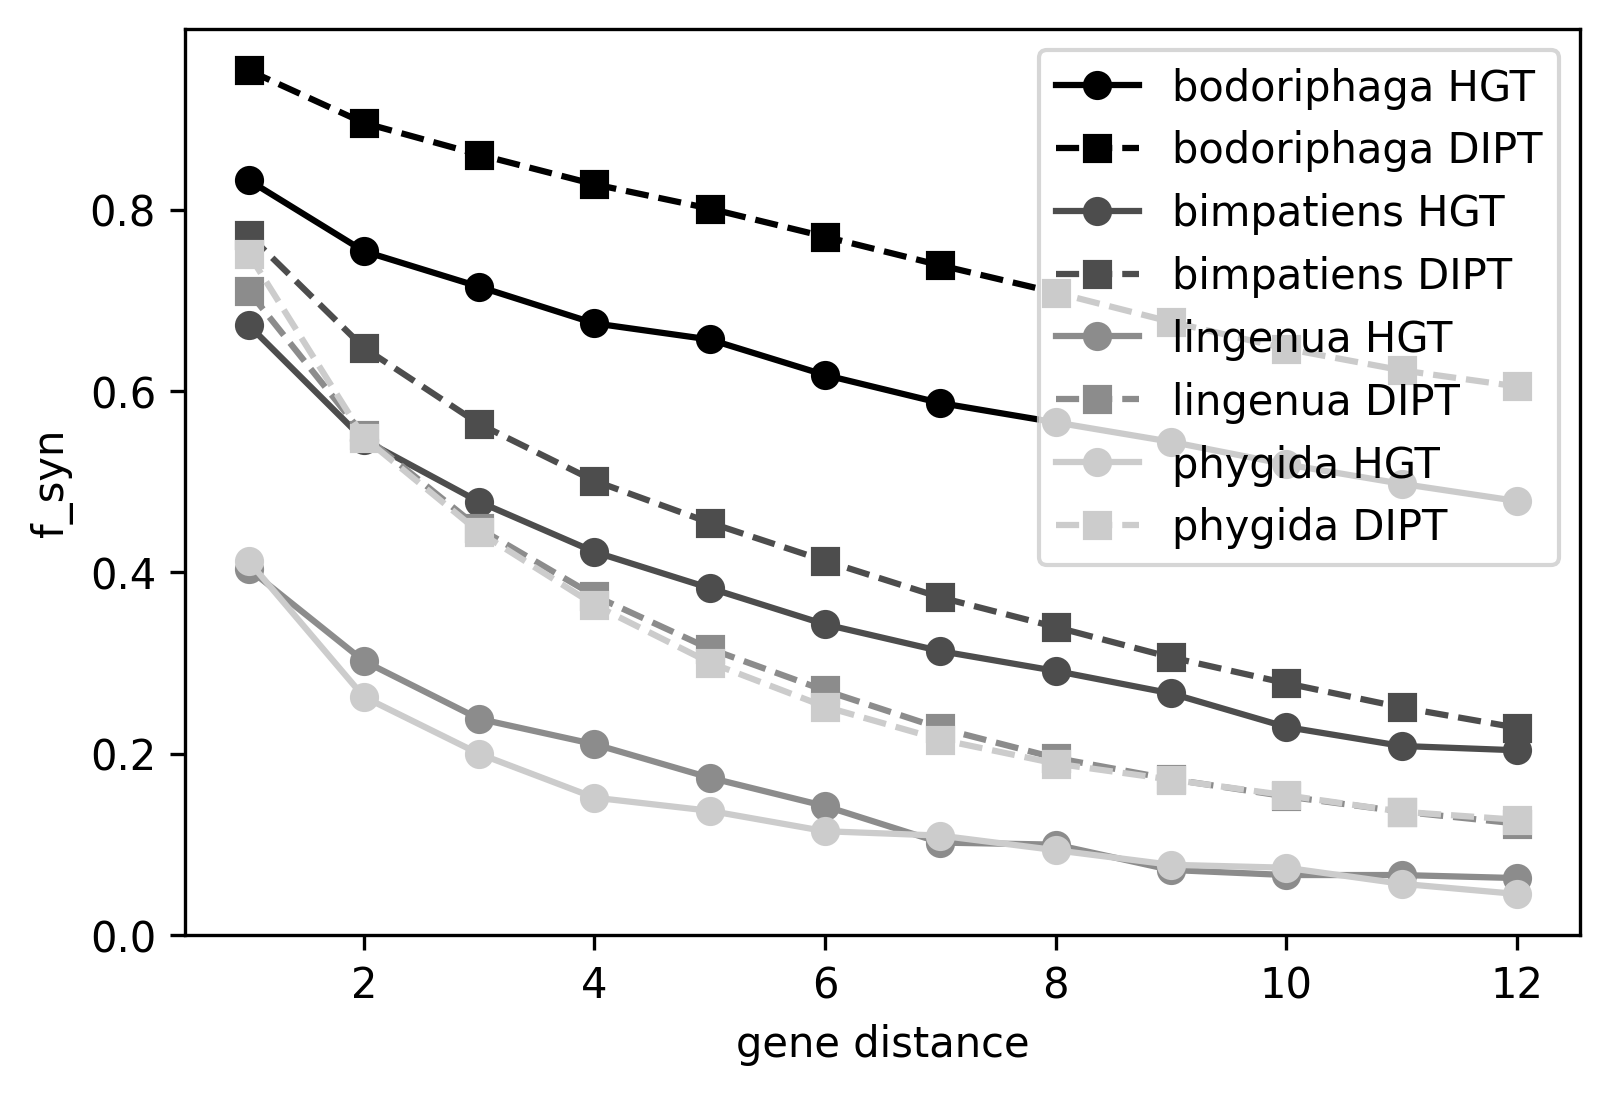

In [66]:
species = ['bodoriphaga', 'bimpatiens', 'lingenua', 'phygida']
greys = ['#000000', '#4D4D4D', '#8C8C8C', '#CCCCCC']

for s, c in zip(species, greys):
    plt.plot(
        syndf['gene distance'],
        syndf[f'{s}_f_syn_hgt'],
        marker='o',
        color=c,
        linestyle='-',
        label=f'{s} HGT'
    )

    plt.plot(
        syndf['gene distance'],
        syndf[f'{s}_f_syn_dipt'],
        marker='s',
        color=c,
        linestyle='--',
        label=f'{s} DIPT'
    )

plt.xlabel('gene distance')
plt.ylabel('f_syn')
plt.legend()
plt.savefig('figures/synteny_plot.svg',format='svg')

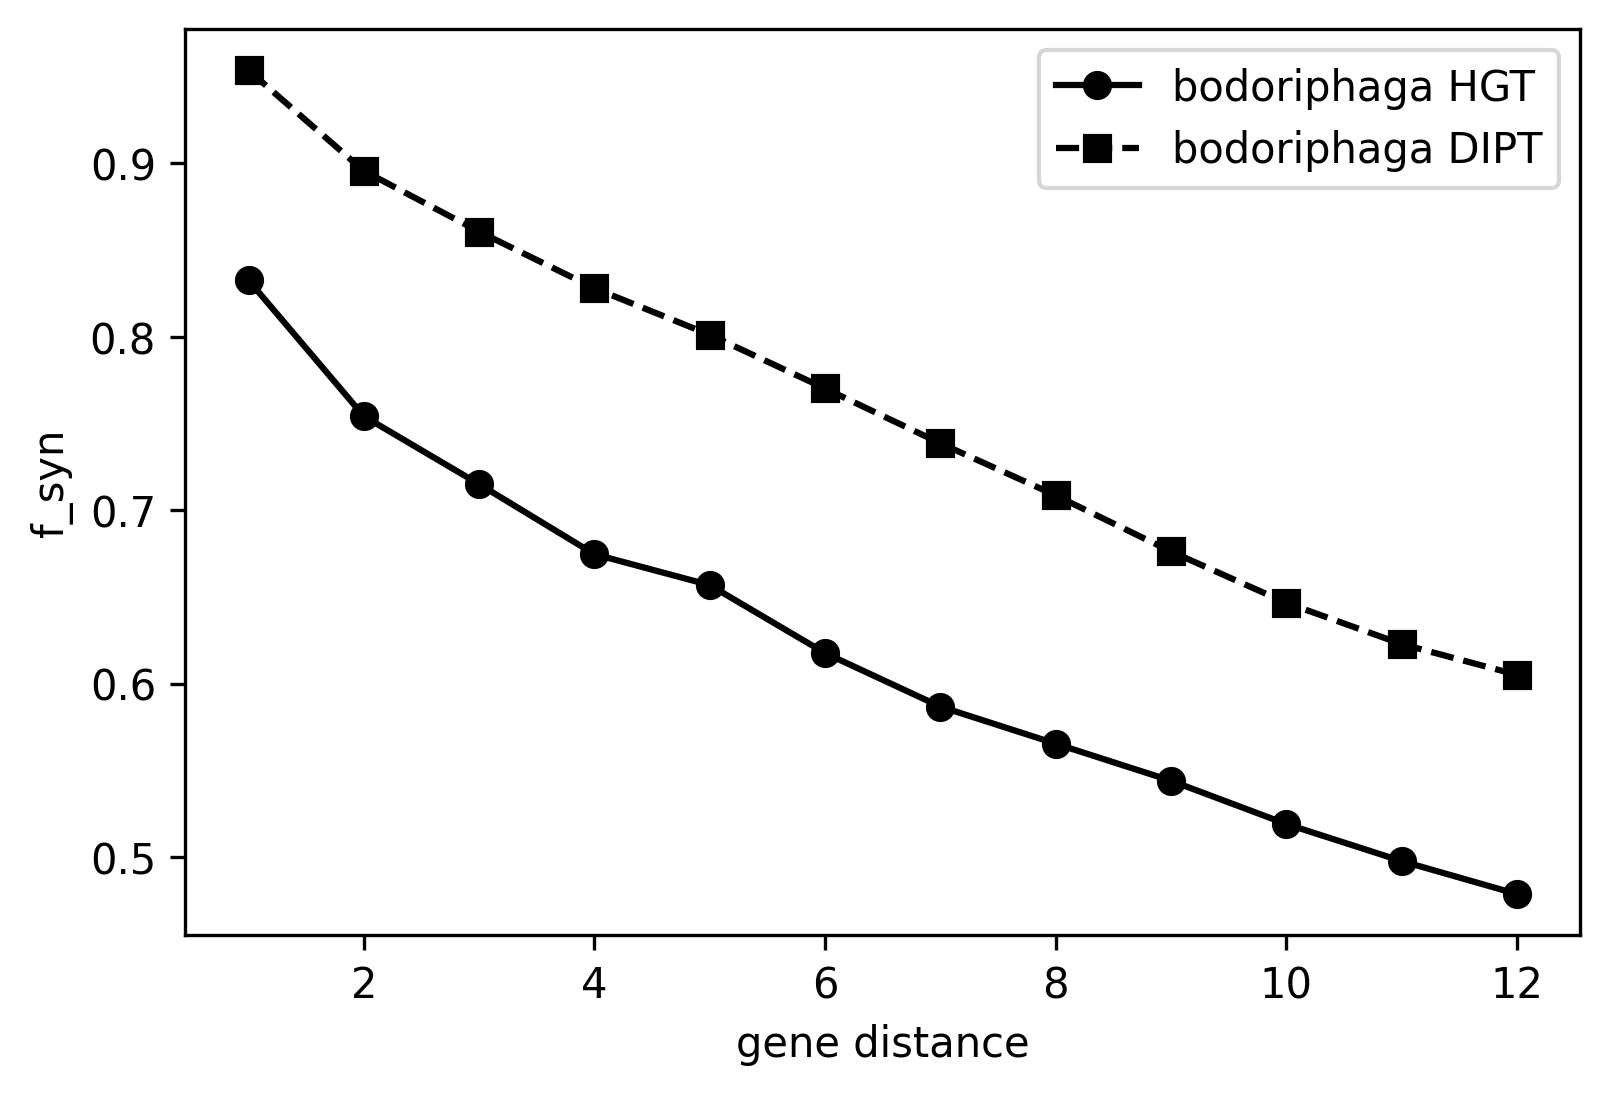

In [67]:
species = ['bodoriphaga']
greys = ['#000000', '#4D4D4D', '#8C8C8C', '#CCCCCC']

for s, c in zip(species, greys):
    plt.plot(
        syndf['gene distance'],
        syndf[f'{s}_f_syn_hgt'],
        marker='o',
        color=c,
        linestyle='-',
        label=f'{s} HGT'
    )

    plt.plot(
        syndf['gene distance'],
        syndf[f'{s}_f_syn_dipt'],
        marker='s',
        color=c,
        linestyle='--',
        label=f'{s} DIPT'
    )

plt.xlabel('gene distance')
plt.ylabel('f_syn')
plt.legend()
plt.savefig('figures/odoriphaga_only_synteny_plot.svg',format='svg')